# Day 04 — YouTube Video Performance Analyzer: analysis

Relevance-ranked snapshot of 244 public data/AI-adjacent YouTube videos, fetched 2026-11-08 via the YouTube Data API v3 (5 fixed queries × 50 results, order=relevance). All comparisons use medians, never means. Performance patterns here describe this sampled set of public videos. They are descriptive, not causal, and are not a guarantee of future performance.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = None


def _find_root(start=None):
    """Resolve the project root from this notebook's own location.

    Uses __file__ when present (test harness sets it to the notebook
    path); otherwise falls back to the working directory and walks up
    checking for data/processed/videos.csv. A copy executed outside
    the project fails with a clear FileNotFoundError.
    """
    if start is None:
        start = globals().get("__file__")
    here = Path(start).resolve().parent if start else Path.cwd()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "processed" / "videos.csv").exists():
            return candidate
    raise FileNotFoundError(
        "data/processed/videos.csv not found above the notebook location"
    )


PROJECT_ROOT = _find_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from youtube_kpi import build_recommendations  # noqa: E402

PROCESSED = PROJECT_ROOT / "data" / "processed"
CHARTS = PROJECT_ROOT / "outputs" / "charts"
print("Project root:", PROJECT_ROOT)

Project root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-04-youtube-video-performance-analyzer


In [2]:
videos = pd.read_csv(PROCESSED / "videos.csv", parse_dates=["published_at"])
source = json.loads((PROCESSED / "data_source.json").read_text())
print(f"Videos: {len(videos)}  |  Channels: {videos['channel_id'].nunique()}")
print(f"Source: {source['source']}  |  Quota used: {source['quota_units_used']} units")
print(f"Published range: {videos['published_at'].min().date()} to {videos['published_at'].max().date()}")
print(f"Like-count present: {videos['like_count'].notna().mean():.1%}  |  "
      f"Subscriber-count present: {videos['subscriber_count'].notna().mean():.1%}")
print(f"Median views/day: {videos['views_per_day'].median():,.0f}  |  "
      f"Median engagement rate: {videos['engagement_rate'].median() * 100:.2f}%")
print(f"Other-topic share: {(videos['topic'] == 'other').mean():.1%}  |  "
      f"Largest channel share: {videos['channel_id'].value_counts(normalize=True).iloc[0]:.1%}")
videos.head(3)

Videos: 244  |  Channels: 143
Source: live  |  Quota used: 508 units
Published range: 2017-05-19 to 2026-11-07
Like-count present: 97.5%  |  Subscriber-count present: 100.0%
Median views/day: 611  |  Median engagement rate: 2.20%
Other-topic share: 0.0%  |  Largest channel share: 4.1%


,video_id,title,channel_id,channel_title,published_at,days_since_publish,view_count,like_count,comment_count,subscriber_count,...,publish_hour_utc,publish_hour_pacific,publish_dow,channel_size,views_per_day,engagement_rate,like_rate,comment_rate,views_per_subscriber,high_performer
0,yZvFH7B6gKI,What Is Data Analytics? - An Introduction (Ful...,UCzAF54cHk1ZO82af-8E3qOQ,CareerFoundry,2021-03-25 13:13:45+00:00,2053,2354250,53644.0,970.0,310000,...,13,5,Thursday,mid,1146.736483,0.023198,0.022786,0.000412,7.594355,False
1,12aUCxVM0hA,How to Become a $200k Data Analyst in 2026 (Ex...,UCteRPiisgIoHtMgqHegpWAQ,Sundas Khalid,2026-10-17 16:30:10+00:00,21,87339,1520.0,64.0,360000,...,16,8,Saturday,mid,4159.000000,0.018136,0.017403,0.000733,0.242608,True
2,OiOOBuRr6oI,The ONLY Skills Your NEED To Become a Data Ana...,UCBck_6Ly4P7Z2d6m4XxRkeA,Karina Data Scientist,2026-10-12 11:30:35+00:00,26,105624,1268.0,63.0,25000,...,11,3,Monday,small,4062.461538,0.012601,0.012005,0.000596,4.224960,True


## Q1 — Which topics, formats and durations perform best?

Medians with sample sizes. Thin groups (n < 10) are labelled, not trusted.

In [3]:
by_topic = videos.groupby("topic").agg(
    median_views_per_day=("views_per_day", "median"),
    median_engagement_pct=("engagement_rate", lambda s: s.median() * 100),
    n=("video_id", "count"),
).sort_values("median_views_per_day", ascending=False)
by_topic

,median_views_per_day,median_engagement_pct,n
topic,,,
bi_viz,2573.930370,1.990327,3
ai_ml,913.603779,1.916577,68
sql,707.087815,2.240630,39
career,642.360039,2.947777,10
python,488.724221,2.313419,123
general,108.171141,2.140530,1


In [4]:
by_duration = videos.groupby("duration_bucket").agg(
    median_views_per_day=("views_per_day", "median"),
    median_engagement_pct=("engagement_rate", lambda s: s.median() * 100),
    n=("video_id", "count"),
).reindex(["short", "short_form", "medium", "long", "deep_dive"])
by_format = videos.groupby("format").agg(
    median_views_per_day=("views_per_day", "median"),
    median_engagement_pct=("engagement_rate", lambda s: s.median() * 100),
    n=("video_id", "count"),
).sort_values("median_views_per_day", ascending=False)
print(by_duration)
print()
print(by_format)

                 median_views_per_day  median_engagement_pct   n
duration_bucket                                                 
short                      369.480872               2.144173  30
short_form                 287.509259               2.242792  19
medium                     610.211650               2.319805  78
long                       851.036620               2.775425  41
deep_dive                  733.521557               2.121892  76

           median_views_per_day  median_engagement_pct    n
format                                                     
other               1582.303819               2.165472   38
tutorial             596.222641               2.230313  192
explainer            503.541027               1.812446   14


In [5]:
high = videos[videos["high_performer"]]
rest = videos[~videos["high_performer"]]
print(f"Top quartile (n={len(high)}): median {high['views_per_day'].median():,.0f} views/day, "
      f"median engagement {high['engagement_rate'].median() * 100:.2f}%")
print(f"Rest (n={len(rest)}): median {rest['views_per_day'].median():,.0f} views/day, "
      f"median engagement {rest['engagement_rate'].median() * 100:.2f}%")
print("Top-quartile topic mix:", high["topic"].value_counts(normalize=True).round(2).to_dict())
print("Rest topic mix:       ", rest["topic"].value_counts(normalize=True).round(2).to_dict())
print("Top-quartile duration mix:", high["duration_bucket"].value_counts(normalize=True).round(2).to_dict())
print(f"Largest channel in top quartile: {high['channel_id'].value_counts(normalize=True).iloc[0]:.1%}")

Top quartile (n=61): median 3,124 views/day, median engagement 2.01%
Rest (n=183): median 380 views/day, median engagement 2.32%
Top-quartile topic mix: {'ai_ml': 0.48, 'python': 0.38, 'sql': 0.1, 'bi_viz': 0.03, 'career': 0.02}
Rest topic mix:        {'python': 0.55, 'ai_ml': 0.21, 'sql': 0.18, 'career': 0.05, 'bi_viz': 0.01, 'general': 0.01}
Top-quartile duration mix: {'deep_dive': 0.39, 'medium': 0.34, 'long': 0.2, 'short': 0.07}
Largest channel in top quartile: 8.2%


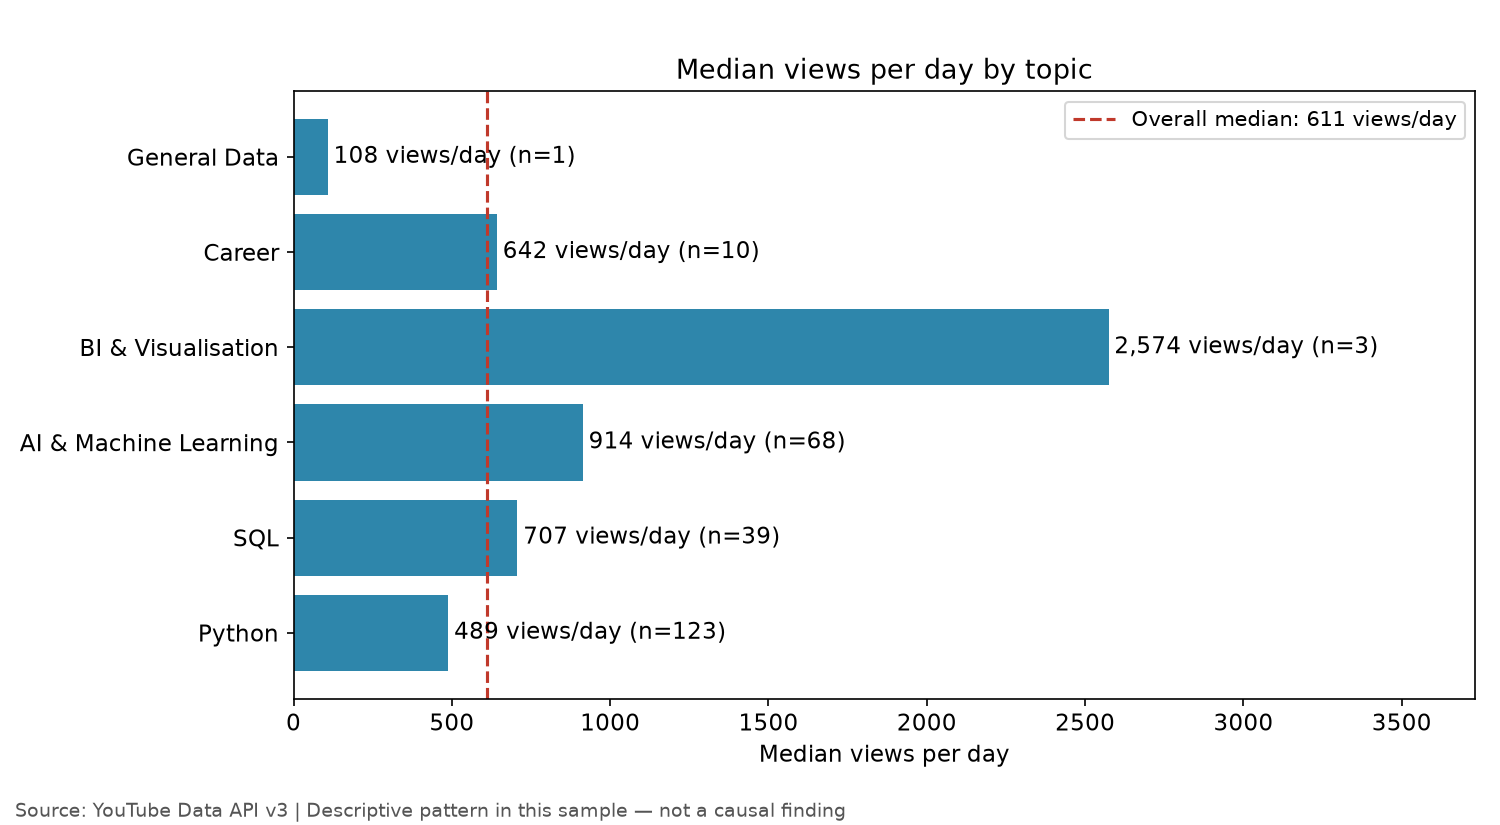

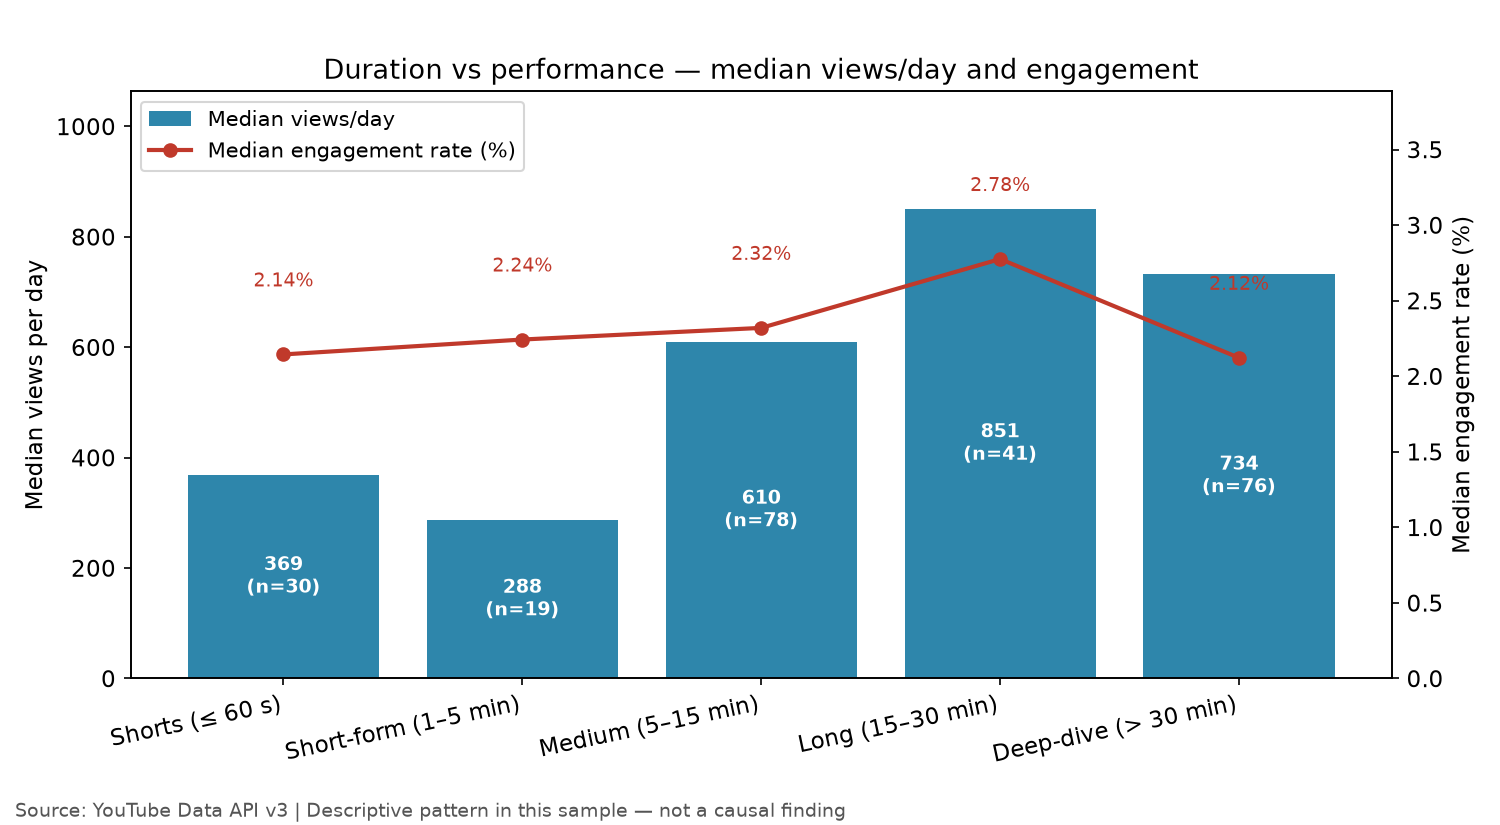

In [6]:
from make_charts import chart_01_views_by_topic, chart_02_duration_vs_performance
chart_01_views_by_topic(videos)
chart_02_duration_vs_performance(videos)
from IPython.display import Image, display
display(Image(str(CHARTS / "01_views_by_topic.png")))
display(Image(str(CHARTS / "02_duration_vs_performance.png")))

## Q2 — When should a creator publish?

Median views per day by weekday and by publish hour (UTC). Most hour/day cells hold only 1–4 videos, and the channel audience timezone is unknown — so any hour pattern is descriptive of this sample, not a best time to post.

In [7]:
by_dow = videos.groupby("publish_dow").agg(
    median_views_per_day=("views_per_day", "median"),
    n=("video_id", "count"),
).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
by_dow

,median_views_per_day,n
publish_dow,,
Monday,825.366833,30
Tuesday,792.682509,47
Wednesday,877.976444,34
Thursday,577.296137,51
Friday,372.593317,41
Saturday,828.868990,24
Sunday,664.254473,17


In [8]:
by_hour = videos.groupby("publish_hour_utc").agg(
    median_views_per_day=("views_per_day", "median"),
    n=("video_id", "count"),
).sort_values("median_views_per_day", ascending=False)
print("Hours with n >= 5 only (thinner hours are not interpretable):")
print(by_hour[by_hour["n"] >= 5])

Hours with n >= 5 only (thinner hours are not interpretable):
                  median_views_per_day   n
publish_hour_utc                          
8                          1396.937764   7
22                          933.506466   6
11                          817.527473  11
16                          807.505488  16
15                          780.266878  25
19                          732.354839  11
13                          693.680055  36
21                          609.297837   5
17                          564.434080  12
12                          508.141887  30
14                          486.645455  39
6                           472.023392   5
18                          357.099640  13


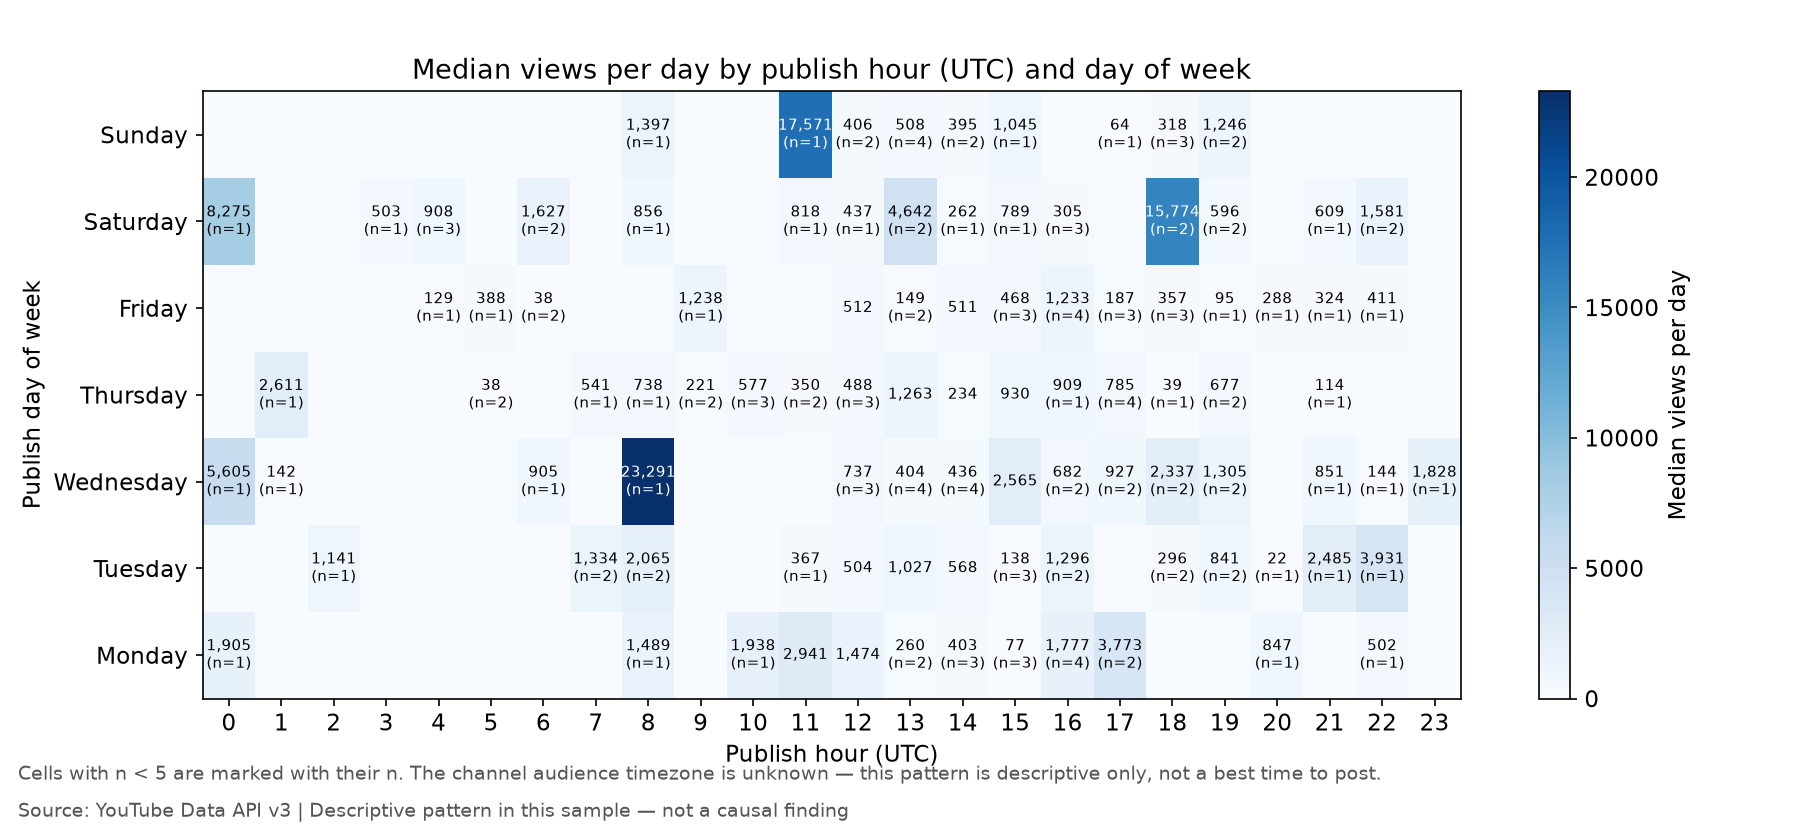

In [9]:
from make_charts import chart_03_publish_time_heatmap
chart_03_publish_time_heatmap(videos)
from IPython.display import Image, display
display(Image(str(CHARTS / "03_publish_time_heatmap.png")))

## Q3 — What concrete recommendations follow, and what is the evidence?

Each recommendation is generated from the group medians by `build_recommendations` (`src/youtube_kpi.py`), cites its numbers, and carries the descriptive-not-causal caveat. No causal verbs are used.

In [10]:
recs = build_recommendations(videos)
for i, r in enumerate(recs, start=1):
    print(f"{i}. {r['recommendation']}")
    print(f"   Evidence: {r['evidence']}")
    print(f"   Sample basis: {r['sample_basis']}")
    print(f"   Caveat: {r['caveat']}\n")
pd.DataFrame(recs)

1. In this sample, long (15–30 min) videos had the highest median views per day of any length group.
   Evidence: median 851 views/day (n=41) vs 611 overall (n=244)
   Sample basis: duration Long (15–30 min) (n=41 of 244)
   Caveat: Descriptive pattern in a relevance-ranked sample of 244 videos — not a causal finding.

2. In this sample, AI & Machine Learning videos had the highest median views per day of any solid topic group (n ≥ 10).
   Evidence: median 914 views/day (n=68) vs 611 overall (n=244)
   Sample basis: topic AI & Machine Learning (n=68 of 244)
   Caveat: Descriptive pattern in a relevance-ranked sample of 244 videos — not a causal finding.

3. In this sample, Career videos had the highest median engagement rate of any topic group.
   Evidence: median engagement 2.95% (n=10) vs 2.20% overall (n=244)
   Sample basis: topic Career (n=10 of 244)
   Caveat: Descriptive pattern in a relevance-ranked sample of 244 videos — not a causal finding.

4. In this sample, tutorials had 

,recommendation,evidence,sample_basis,caveat
0,"In this sample, long (15–30 min) videos had th...",median 851 views/day (n=41) vs 611 overall (n=...,duration Long (15–30 min) (n=41 of 244),Descriptive pattern in a relevance-ranked samp...
1,"In this sample, AI & Machine Learning videos h...",median 914 views/day (n=68) vs 611 overall (n=...,topic AI & Machine Learning (n=68 of 244),Descriptive pattern in a relevance-ranked samp...
2,"In this sample, Career videos had the highest ...",median engagement 2.95% (n=10) vs 2.20% overal...,topic Career (n=10 of 244),Descriptive pattern in a relevance-ranked samp...
3,"In this sample, tutorials had the higher media...",tutorials median 596 views/day (n=192); explai...,format comparison (n=206 of 244),Descriptive pattern in a relevance-ranked samp...
4,"In this sample, the top-quartile videos by vie...",top quartile median engagement 2.01% (n=61) vs...,high performers (top quartile of views per day...,Descriptive pattern in a relevance-ranked samp...
5,"In this sample, videos published on Wednesdays...",median 878 views/day (n=34) vs 611 overall; th...,publish day of week Wednesday (n=34 of 244),Descriptive pattern in a relevance-ranked samp...


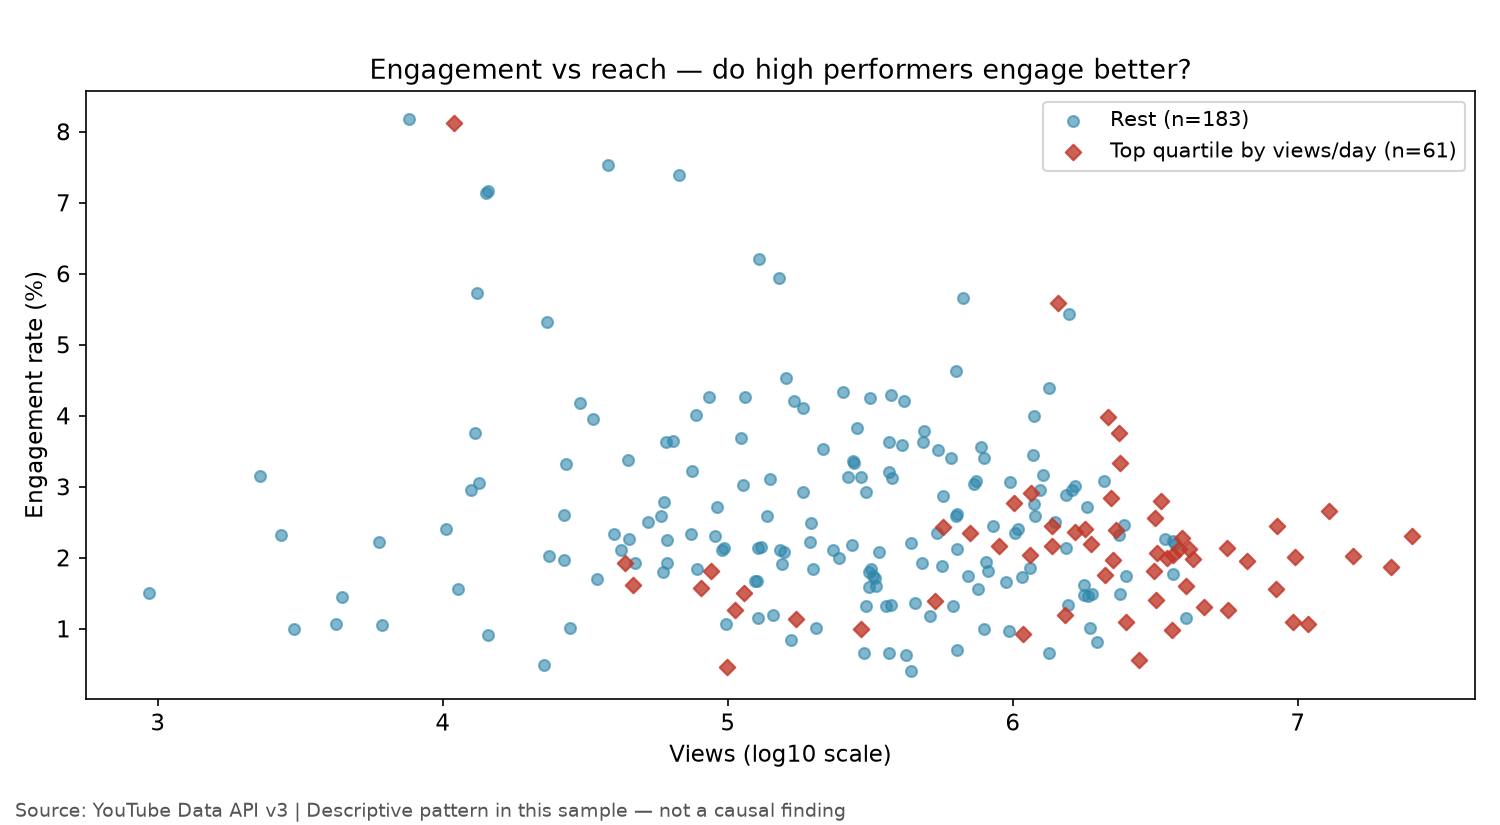

In [11]:
from make_charts import chart_04_engagement_scatter
chart_04_engagement_scatter(videos)
from IPython.display import Image, display
display(Image(str(CHARTS / "04_engagement_scatter.png")))

## Limitations

- Relevance-ranked snapshot as of 2026-11-08, not a date-bounded cohort (the helper sends no publishedAfter/publishedBefore); the sample mixes 2017 and 2026 videos, and `views_per_day` only partly corrects for age.
- Search relevance ranking is undocumented; findings describe the returned set, not all of YouTube.
- No causal claims: a pattern in this cross-sectional sample cannot show that a topic or length causes stronger performance.
- BI & Visualisation (n=3) and General Data (n=1) are too thin for recommendations; the 'Other' topic group is empty (0 videos).
- Comment sentiment is out of scope — no comments endpoint exists in the helper.
- Data from the YouTube Data API v3. Derived rates are basic arithmetic on returned statistics for an offline educational analysis, shown next to the underlying counts.